# Semana 9 — Análisis meticuloso de regresión e IA para analítica
## Predicción de popularidad de canciones antes del lanzamiento

**Objetivo del análisis:** documentar la calidad del dataset, prevenir fuga de información, comparar los cuatro experimentos de regresión registrados (RF1, RF2, HGB3 y HGB4), evaluar el error y el sesgo, analizar segmentos, y producir evidencia para el informe.

**Importante sobre la trazabilidad:** las métricas RF1, RF2, HGB3 y HGB4 de la sección comparativa se transcriben del registro de experimentos que se había construido a partir de las fichas/salidas disponibles. En el registro, algunas filas estaban marcadas como pendientes de reconfirmación con la salida original. Por tanto, este notebook las presenta como **resultados registrados**, no como una reproducción independiente de los cuatro entrenamientos. HGB4 tiene sus parámetros conocidos documentados. No se inventan parámetros exactos para RF1, RF2 y HGB3 cuando no están disponibles en el script actual.

El dataset se trata como sintético; los resultados describen este conjunto y no prueban causalidad ni garantizan generalización a música real.

## 0. Preparación y reproducibilidad
Ejecuta las celdas de arriba hacia abajo. El notebook busca `data/canciones.csv` desde la raíz del proyecto o desde la carpeta padre. Los gráficos se crean con Matplotlib y las tablas muestran los resultados calculados.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
candidatas = [
    Path("data/canciones.csv"),
    Path("../data/canciones.csv"),
    Path("demo-reg-clas-canciones-main/data/canciones.csv"),
]
RUTA_DATOS = next((p for p in candidatas if p.exists()), None)
if RUTA_DATOS is None:
    raise FileNotFoundError("No se encontró data/canciones.csv. Abre el notebook desde la raíz del proyecto o ajusta RUTA_DATOS.")
datos = pd.read_csv(RUTA_DATOS).sort_values("anio", kind="stable").reset_index(drop=True)
print("Archivo:", RUTA_DATOS.resolve())
print(f"Dimensiones: {datos.shape[0]:,} filas × {datos.shape[1]} columnas")
display(datos.head())

Archivo: C:\Users\USER\Downloads\demo-reg-clas-canciones-main\data\canciones.csv
Dimensiones: 2,000 filas × 13 columnas


,bailabilidad,energia,valencia,acustica,tempo,duracion_min,volumen_db,anio,colaboracion,genero,reproducciones_sem1,popularidad,es_hit
0,0.376,0.648,0.425,0.119,96.1,2.20,-4.0,1995,0,indie,426829,60.2,0
1,0.828,0.824,0.377,0.154,109.2,2.68,-6.5,1995,1,indie,534264,66.1,0
2,0.189,0.761,0.300,0.373,200.0,4.39,-12.2,1995,0,urbano,256039,46.3,0
3,0.845,0.559,0.759,0.084,149.3,2.43,-6.3,1995,0,pop,561896,67.9,0
4,0.429,0.893,0.419,0.441,134.3,5.23,-8.8,1995,0,electronica,459289,63.6,0


## 1. Diccionario práctico de variables y definición del problema

In [2]:
diccionario = pd.DataFrame([
    ("bailabilidad","Numérica","Antes del lanzamiento","Entrada"),
    ("energia","Numérica","Antes del lanzamiento","Entrada"),
    ("valencia","Numérica","Antes del lanzamiento","Entrada"),
    ("acustica","Numérica","Antes del lanzamiento","Entrada"),
    ("tempo","Numérica","Antes del lanzamiento","Entrada"),
    ("duracion_min","Numérica","Antes del lanzamiento","Entrada"),
    ("volumen_db","Numérica","Antes del lanzamiento","Entrada"),
    ("anio","Entera","Antes del lanzamiento","Entrada"),
    ("colaboracion","Binaria","Antes del lanzamiento","Entrada"),
    ("genero","Categórica","Antes del lanzamiento","Entrada"),
    ("reproducciones_sem1","Entera","Después del lanzamiento","Excluir: fuga temporal"),
    ("popularidad","Numérica 0–100","Objetivo","Objetivo de regresión"),
    ("es_hit","Binaria","Derivada de popularidad","Excluir: fuga del objetivo"),
], columns=["variable","tipo","momento/disponibilidad","uso en regresión"])
display(diccionario)

,variable,tipo,momento/disponibilidad,uso en regresión
0,bailabilidad,Numérica,Antes del lanzamiento,Entrada
1,energia,Numérica,Antes del lanzamiento,Entrada
2,valencia,Numérica,Antes del lanzamiento,Entrada
3,acustica,Numérica,Antes del lanzamiento,Entrada
4,tempo,Numérica,Antes del lanzamiento,Entrada
5,duracion_min,Numérica,Antes del lanzamiento,Entrada
6,volumen_db,Numérica,Antes del lanzamiento,Entrada
7,anio,Entera,Antes del lanzamiento,Entrada
8,colaboracion,Binaria,Antes del lanzamiento,Entrada
9,genero,Categórica,Antes del lanzamiento,Entrada


**Pregunta de negocio:** antes del lanzamiento, ¿qué popularidad podría alcanzar una canción y cómo podría esa estimación apoyar la asignación de promoción?

**Objetivo de regresión:** `popularidad`.

**Entradas permitidas:** `bailabilidad`, `energia`, `valencia`, `acustica`, `tempo`, `duracion_min`, `volumen_db`, `anio`, `colaboracion`, `genero`.

**Variables excluidas:** `reproducciones_sem1` sucede después del lanzamiento; `es_hit` se deriva del objetivo. Incluirlas produciría fuga de información y una evaluación engañosamente optimista.

## 2. Auditoría de calidad de datos

In [3]:
print("Tipos de datos:")
display(datos.dtypes.rename("tipo").to_frame())
calidad = pd.DataFrame({
    "tipo": datos.dtypes.astype(str),
    "nulos": datos.isna().sum(),
    "porcentaje_nulos": (datos.isna().mean()*100).round(2),
    "valores_unicos": datos.nunique(),
})
display(calidad)
print("Filas duplicadas completas:", int(datos.duplicated().sum()))
print("Años disponibles:", int(datos["anio"].min()), "a", int(datos["anio"].max()))
print("Número de géneros:", datos["genero"].nunique())
display(datos.describe(include="all").T)

Tipos de datos:


,tipo
bailabilidad,float64
energia,float64
valencia,float64
acustica,float64
tempo,float64
duracion_min,float64
volumen_db,float64
anio,int64
colaboracion,int64
genero,object


,tipo,nulos,porcentaje_nulos,valores_unicos
bailabilidad,float64,0,0.0,762
energia,float64,0,0.0,751
valencia,float64,0,0.0,793
acustica,float64,0,0.0,721
tempo,float64,0,0.0,857
duracion_min,float64,0,0.0,367
volumen_db,float64,0,0.0,161
anio,int64,0,0.0,31
colaboracion,int64,0,0.0,2
genero,object,0,0.0,5


Filas duplicadas completas: 0
Años disponibles: 1995 a 2025
Número de géneros: 5


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
bailabilidad,2000.0,NaN,NaN,NaN,0.524307,0.216249,0.019,0.3575,0.533,0.69525,0.994
energia,2000.0,NaN,NaN,NaN,0.564995,0.210052,0.03,0.41075,0.5785,0.73225,0.995
valencia,2000.0,NaN,NaN,NaN,0.490019,0.227326,0.016,0.311,0.491,0.6715,0.976
acustica,2000.0,NaN,NaN,NaN,0.338046,0.203397,0.001,0.17875,0.31,0.47725,0.948
tempo,2000.0,NaN,NaN,NaN,120.141,24.550743,60.0,103.4,119.3,136.3,200.0
duracion_min,2000.0,NaN,NaN,NaN,3.4985,0.800698,1.5,2.95,3.5,4.05,6.15
volumen_db,2000.0,NaN,NaN,NaN,-8.0219,3.018854,-18.8,-10.1,-8.0,-6.0,0.0
anio,2000.0,NaN,NaN,NaN,2010.477,8.951343,1995.0,2003.0,2011.0,2018.0,2025.0
colaboracion,2000.0,NaN,NaN,NaN,0.2585,0.43792,0.0,0.0,0.0,1.0,1.0
genero,2000,5,pop,616,NaN,NaN,NaN,NaN,NaN,NaN,NaN


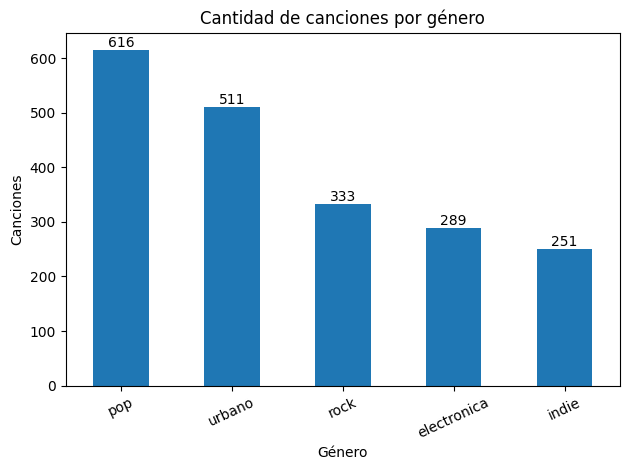

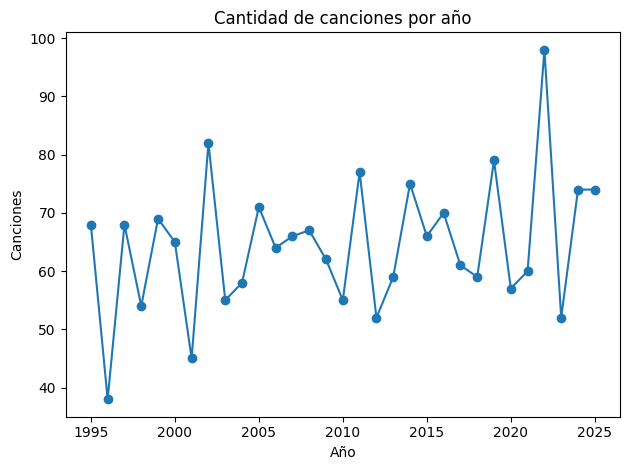

In [4]:
# Distribución por género y año
conteo_genero = datos["genero"].value_counts().sort_values(ascending=False)
ax = conteo_genero.plot(kind="bar", title="Cantidad de canciones por género", rot=25)
ax.set_ylabel("Canciones")
ax.set_xlabel("Género")
for i, v in enumerate(conteo_genero.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

por_anio = datos.groupby("anio").size()
ax = por_anio.plot(kind="line", marker="o", title="Cantidad de canciones por año")
ax.set_ylabel("Canciones")
ax.set_xlabel("Año")
plt.tight_layout()
plt.show()

### Interpretación de calidad
- Se observaron 2.000 filas y 13 columnas.
- En la revisión reportada: 0 nulos y 0 filas duplicadas.
- El dataset contiene cinco géneros, con mayor representación de pop y urbano; esta distribución desigual importa al interpretar errores por segmento.
- La ausencia de nulos/duplicados no significa que el dataset esté libre de sesgos, errores de medición o limitaciones de representatividad.

## 3. Distribuciones, correlaciones y posibles valores extremos

In [5]:
variables_numericas = datos.select_dtypes(include="number").columns.tolist()
display(datos[variables_numericas].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
bailabilidad,2000.0,0.52,0.22,0.02,0.36,0.53,0.70,0.99
energia,2000.0,0.56,0.21,0.03,0.41,0.58,0.73,1.00
valencia,2000.0,0.49,0.23,0.02,0.31,0.49,0.67,0.98
acustica,2000.0,0.34,0.20,0.00,0.18,0.31,0.48,0.95
tempo,2000.0,120.14,24.55,60.00,103.40,119.30,136.30,200.00
duracion_min,2000.0,3.50,0.80,1.50,2.95,3.50,4.05,6.15
volumen_db,2000.0,-8.02,3.02,-18.80,-10.10,-8.00,-6.00,0.00
anio,2000.0,2010.48,8.95,1995.00,2003.00,2011.00,2018.00,2025.00
colaboracion,2000.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00
reproducciones_sem1,2000.0,428917.57,180940.89,18475.00,295842.25,413708.50,543565.25,1121386.00


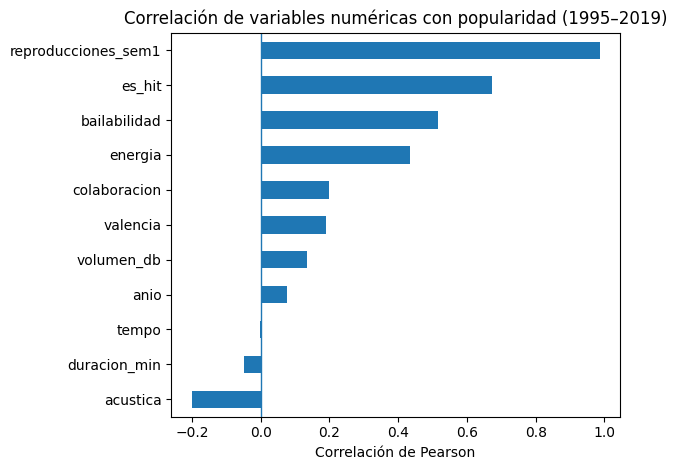

,correlación
reproducciones_sem1,0.986
es_hit,0.673
bailabilidad,0.517
energia,0.434
colaboracion,0.199
valencia,0.189
volumen_db,0.134
anio,0.076
tempo,-0.002
duracion_min,-0.048


In [6]:
# Correlaciones calculadas sobre el periodo de entrenamiento para no inspeccionar el test al tomar decisiones.
train_mask = datos["anio"] < 2020
train_datos = datos.loc[train_mask]
corr_objetivo = train_datos.select_dtypes(include="number").corr()["popularidad"].drop("popularidad").sort_values()
ax = corr_objetivo.plot(kind="barh", title="Correlación de variables numéricas con popularidad (1995–2019)")
ax.set_xlabel("Correlación de Pearson")
ax.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()
display(corr_objetivo.sort_values(ascending=False).to_frame("correlación").round(3))

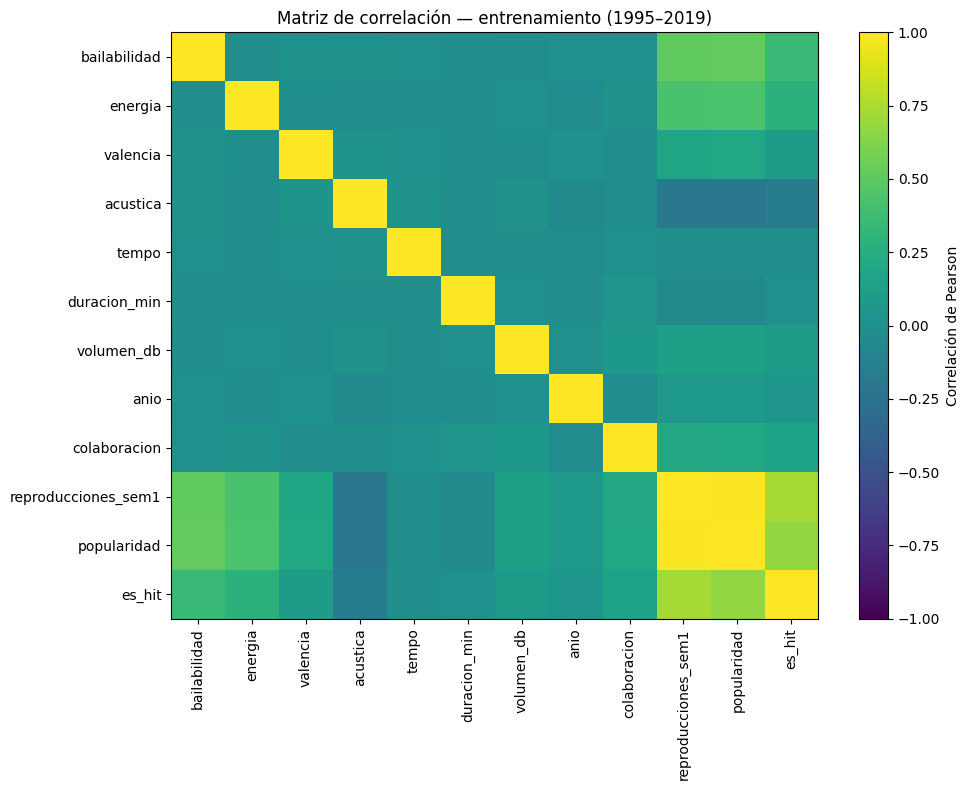

In [7]:
# Matriz de correlación numérica del periodo de entrenamiento
matriz_corr = train_datos.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(matriz_corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz_corr.columns)))
ax.set_xticklabels(matriz_corr.columns, rotation=90)
ax.set_yticks(range(len(matriz_corr.index)))
ax.set_yticklabels(matriz_corr.index)
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación — entrenamiento (1995–2019)")
plt.tight_layout()
plt.show()

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,posibles_extremos
7,popularidad,48.60,67.30,18.70,20.55,95.35,10
4,tempo,103.20,135.70,32.50,54.45,184.45,8
5,duracion_min,2.96,4.05,1.09,1.33,5.68,7
6,volumen_db,-10.00,-6.00,4.00,-16.00,0.00,5
3,acustica,0.18,0.48,0.30,-0.26,0.92,1
2,valencia,0.32,0.68,0.36,-0.22,1.22,0
0,bailabilidad,0.36,0.69,0.33,-0.14,1.19,0
1,energia,0.42,0.73,0.32,-0.06,1.21,0


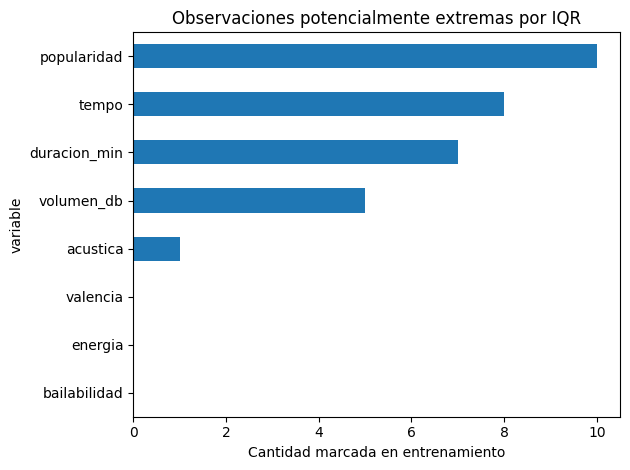

In [8]:
# Regla IQR: marca observaciones potencialmente extremas, no necesariamente errores.
cols_iqr = ["bailabilidad","energia","valencia","acustica","tempo","duracion_min","volumen_db","popularidad"]
extremos = []
for c in cols_iqr:
    q1, q3 = train_datos[c].quantile([0.25, 0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    n = int(((train_datos[c] < lo) | (train_datos[c] > hi)).sum())
    extremos.append({"variable":c,"Q1":q1,"Q3":q3,"IQR":iqr,"limite_inferior":lo,"limite_superior":hi,"posibles_extremos":n})
extremos_df = pd.DataFrame(extremos).sort_values("posibles_extremos", ascending=False)
display(extremos_df.round(2))
ax = extremos_df.sort_values("posibles_extremos").plot.barh(x="variable", y="posibles_extremos", legend=False, title="Observaciones potencialmente extremas por IQR")
ax.set_xlabel("Cantidad marcada en entrenamiento")
plt.tight_layout()
plt.show()

### Hallazgos descriptivos
En entrenamiento, las correlaciones reportadas con popularidad fueron: `bailabilidad` 0,517; `energia` 0,434; `acustica` −0,201; `colaboracion` 0,199; `valencia` 0,189; `volumen_db` 0,134; `anio` 0,076; `tempo` −0,002; `duracion_min` −0,048. `reproducciones_sem1` (0,986) y `es_hit` (0,673) también aparecen muy correlacionadas, pero se excluyen por fuga temporal/derivación del objetivo.

El IQR señaló 10 valores potencialmente extremos en popularidad, 8 en tempo, 7 en duración, 5 en volumen y 1 en acústica. No se eliminan automáticamente: se recomienda inspeccionar su plausibilidad y conservarlos si son válidos.

## 4. Diseño de evaluación temporal y control de fuga

In [9]:
CORTE = 2020
mascara_train = datos["anio"] < CORTE
mascara_test = ~mascara_train
print(f"Entrenamiento: n={mascara_train.sum()} | {datos.loc[mascara_train,'anio'].min()}–{datos.loc[mascara_train,'anio'].max()}")
print(f"Prueba temporal: n={mascara_test.sum()} | {datos.loc[mascara_test,'anio'].min()}–{datos.loc[mascara_test,'anio'].max()}")
print("Proporción test:", round(mascara_test.mean()*100, 2), "%")
assert datos.loc[mascara_train, "anio"].max() < datos.loc[mascara_test, "anio"].min()

Entrenamiento: n=1585 | 1995–2019
Prueba temporal: n=415 | 2020–2025
Proporción test: 20.75 %


La partición evita mezclar aleatoriamente años pasados y futuros. El preprocesamiento (codificación de género y escalado) debe ajustarse exclusivamente con entrenamiento, idealmente dentro de un `Pipeline`. El script de entrenamiento revisado usa `pipeline.fit(X.loc[entrenamiento], y.loc[entrenamiento])` y predice después sobre el periodo de prueba.

## 5. Comparativa principal de los cuatro experimentos de regresión

In [10]:
# Resultados registrados en el registro comparativo de la Semana 9.
# Convención uniforme de sesgo para esta tabla: predicción - valor real.
experimentos = pd.DataFrame([
    {"experimento":"RF1","algoritmo":"Random Forest","MAE":6.96,"RMSE":8.69,"R2":0.584,"sesgo_pred_menos_real":-2.09},
    {"experimento":"RF2","algoritmo":"Random Forest (experimento 2)","MAE":7.10,"RMSE":8.85,"R2":0.568,"sesgo_pred_menos_real":-2.29},
    {"experimento":"HGB3","algoritmo":"HistGradientBoosting","MAE":6.36,"RMSE":8.03,"R2":0.645,"sesgo_pred_menos_real":-1.96},
    {"experimento":"HGB4","algoritmo":"HistGradientBoosting (experimento 4)","MAE":6.39,"RMSE":7.98,"R2":0.649,"sesgo_pred_menos_real":-2.06},
])
baseline_mae = 10.44
experimentos["reduccion_MAE_vs_baseline_pct"] = (baseline_mae-experimentos["MAE"])/baseline_mae*100
display(experimentos.round(3).sort_values("MAE"))

,experimento,algoritmo,MAE,RMSE,R2,sesgo_pred_menos_real,reduccion_MAE_vs_baseline_pct
2,HGB3,HistGradientBoosting,6.36,8.03,0.645,-1.96,39.080
3,HGB4,HistGradientBoosting (experimento 4),6.39,7.98,0.649,-2.06,38.793
0,RF1,Random Forest,6.96,8.69,0.584,-2.09,33.333
1,RF2,Random Forest (experimento 2),7.10,8.85,0.568,-2.29,31.992


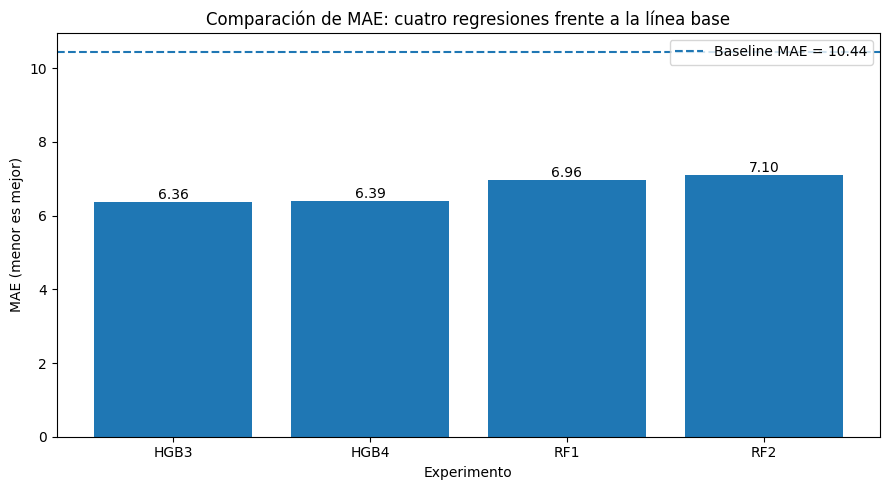

In [11]:
fig, ax = plt.subplots(figsize=(9,5))
ordem = experimentos.sort_values("MAE")
barras = ax.bar(ordem["experimento"], ordem["MAE"])
ax.axhline(baseline_mae, linestyle="--", label=f"Baseline MAE = {baseline_mae:.2f}")
ax.set_title("Comparación de MAE: cuatro regresiones frente a la línea base")
ax.set_ylabel("MAE (menor es mejor)")
ax.set_xlabel("Experimento")
ax.legend()
for b in barras:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.08, f"{b.get_height():.2f}", ha="center")
plt.tight_layout()
plt.show()

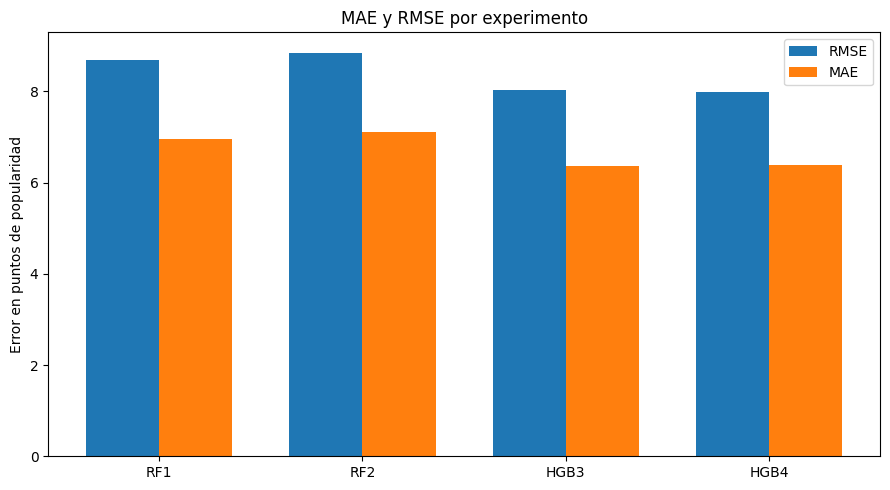

In [12]:
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(len(experimentos))
w = 0.36
ax.bar(x-w/2, experimentos["RMSE"], width=w, label="RMSE")
ax.bar(x+w/2, experimentos["MAE"], width=w, label="MAE")
ax.set_xticks(x)
ax.set_xticklabels(experimentos["experimento"])
ax.set_title("MAE y RMSE por experimento")
ax.set_ylabel("Error en puntos de popularidad")
ax.legend()
plt.tight_layout()
plt.show()

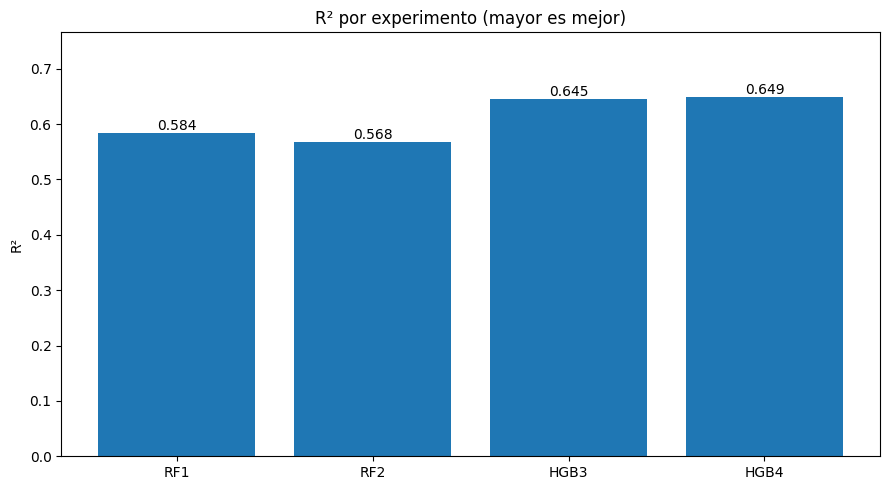

In [13]:
fig, ax = plt.subplots(figsize=(9,5))
bars = ax.bar(experimentos["experimento"], experimentos["R2"])
ax.set_ylim(0, max(experimentos["R2"])*1.18)
ax.set_title("R² por experimento (mayor es mejor)")
ax.set_ylabel("R²")
for b, val in zip(bars, experimentos["R2"]):
    ax.text(b.get_x()+b.get_width()/2, val+0.006, f"{val:.3f}", ha="center")
plt.tight_layout()
plt.show()

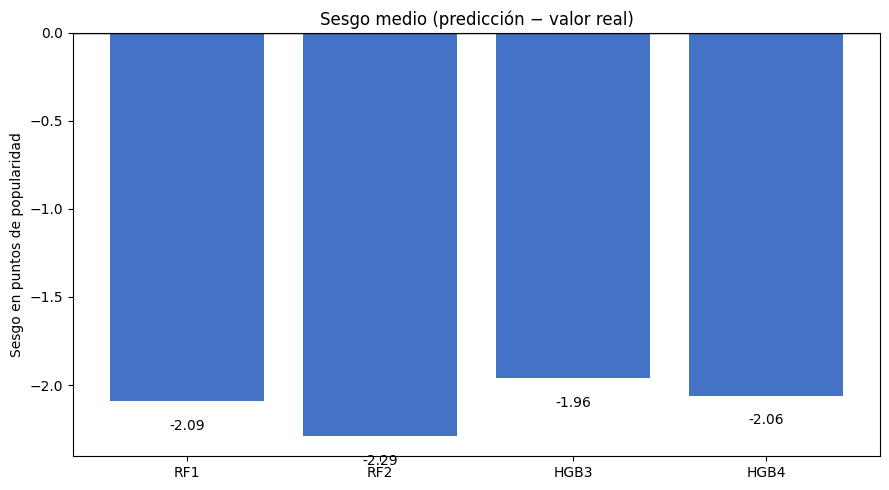

In [14]:
fig, ax = plt.subplots(figsize=(9,5))
colors = ["#4472C4" if v < 0 else "#ED7D31" for v in experimentos["sesgo_pred_menos_real"]]
bars = ax.bar(experimentos["experimento"], experimentos["sesgo_pred_menos_real"], color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Sesgo medio (predicción − valor real)")
ax.set_ylabel("Sesgo en puntos de popularidad")
for b, val in zip(bars, experimentos["sesgo_pred_menos_real"]):
    ax.text(b.get_x()+b.get_width()/2, val-0.10, f"{val:.2f}", ha="center", va="top")
plt.tight_layout()
plt.show()

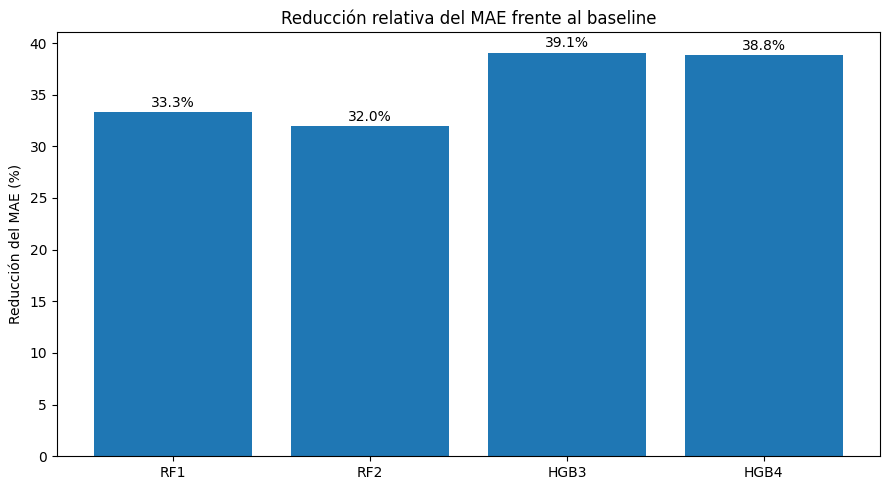

In [15]:
fig, ax = plt.subplots(figsize=(9,5))
bars = ax.bar(experimentos["experimento"], experimentos["reduccion_MAE_vs_baseline_pct"])
ax.set_title("Reducción relativa del MAE frente al baseline")
ax.set_ylabel("Reducción del MAE (%)")
for b, val in zip(bars, experimentos["reduccion_MAE_vs_baseline_pct"]):
    ax.text(b.get_x()+b.get_width()/2, val+0.5, f"{val:.1f}%", ha="center")
plt.tight_layout()
plt.show()

### Lectura comparativa de resultados registrados
- **RF1:** MAE 6,96; RMSE 8,69; R² 0,584. Supera claramente la línea base, pero presenta más error que ambos HGB.
- **RF2:** MAE 7,10; RMSE 8,85; R² 0,568. Es el peor de los cuatro en las tres métricas principales, aunque sigue superando el baseline MAE 10,44.
- **HGB3:** MAE 6,36, el menor MAE. Es la mejor opción si se prioriza el error absoluto promedio.
- **HGB4:** RMSE 7,98 (el menor) y R² 0,649 (el mayor). Tiene MAE 6,39, apenas 0,03 puntos por encima de HGB3. Puede preferirse si se valora más la penalización de errores grandes y el ajuste global.
- **Sesgo:** todos tienen sesgo medio negativo en convención predicción − real (aprox. −1,96 a −2,29), lo que indica subestimación promedio de alrededor de 2 puntos. El sesgo no describe por sí solo la dispersión de los errores.
- **Contra baseline:** los cuatro reducen el MAE aproximadamente entre 31,9 % y 39,1 %.

## 6. Resumen ejecutivo numérico

In [16]:
resumen = experimentos.copy()
resumen["posición_MAE"] = resumen["MAE"].rank(method="min").astype(int)
resumen["posición_RMSE"] = resumen["RMSE"].rank(method="min").astype(int)
resumen["posición_R2"] = resumen["R2"].rank(ascending=False, method="min").astype(int)
display(resumen[["experimento","MAE","posición_MAE","RMSE","posición_RMSE","R2","posición_R2","reduccion_MAE_vs_baseline_pct"]].round(3).sort_values("posición_MAE"))
print("Mejor MAE:", resumen.loc[resumen["MAE"].idxmin(), "experimento"])
print("Mejor RMSE:", resumen.loc[resumen["RMSE"].idxmin(), "experimento"])
print("Mayor R²:", resumen.loc[resumen["R2"].idxmax(), "experimento"])
print("Baseline MAE:", baseline_mae)

,experimento,MAE,posición_MAE,RMSE,posición_RMSE,R2,posición_R2,reduccion_MAE_vs_baseline_pct
2,HGB3,6.36,1,8.03,2,0.645,2,39.080
3,HGB4,6.39,2,7.98,1,0.649,1,38.793
0,RF1,6.96,3,8.69,3,0.584,3,33.333
1,RF2,7.10,4,8.85,4,0.568,4,31.992


Mejor MAE: HGB3
Mejor RMSE: HGB4
Mayor R²: HGB4
Baseline MAE: 10.44


**No existe un ganador absoluto sin definir el criterio:** HGB3 gana por MAE; HGB4 gana por RMSE y R². La diferencia de MAE entre HGB3 y HGB4 es mínima (0,03 puntos). Conviene documentar el criterio de selección en el informe en lugar de escoger solo por una métrica.

## 7. Errores por género: qué revisar y qué no se puede concluir

In [17]:
# La ficha HGB4 registraba MAE y sesgo por género. Se muestran como evidencia de diagnóstico.
# Los valores por género no se completan aquí porque no se cuenta con la ficha completa de segmentos en el registro CSV.
segmentos_registrados = pd.DataFrame([
    {"experimento":"HGB4","segmento":"Por género","estado":"Revisar ficha del modelo","nota":"No imputar valores no disponibles en registro_semana9.csv."}
])
display(segmentos_registrados)

,experimento,segmento,estado,nota
0,HGB4,Por género,Revisar ficha del modelo,No imputar valores no disponibles en registro_...


Para una conclusión rigurosa por género se deben recuperar los valores `por_genero` de la ficha del artefacto HGB4 o reentrenar el modelo con la misma versión de scikit-learn y configuración y recalcularlos. No es correcto fabricar esas métricas a partir de métricas globales.

## 8. Ingeniería de variables e importancia

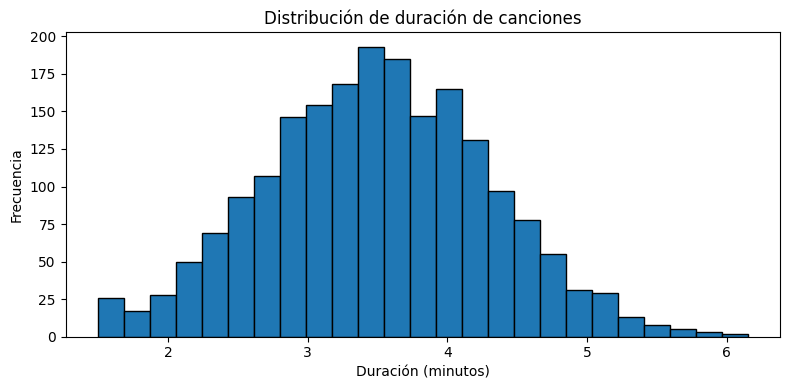

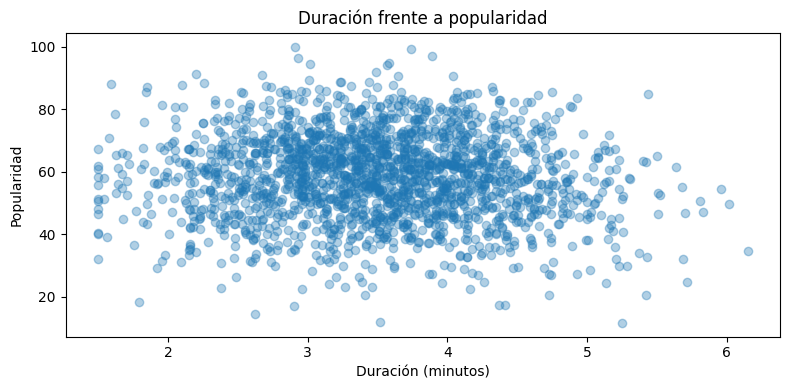

In [18]:
# La variable derivada duracion_c2 se define fila a fila: (duracion_min - 3.5)^2.
# No aprende parámetros de otros registros, por lo que no introduce fuga por sí misma.
datos["duracion_c2"] = (datos["duracion_min"] - 3.5)**2
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(datos["duracion_min"], bins=25, edgecolor="black")
ax.set_title("Distribución de duración de canciones")
ax.set_xlabel("Duración (minutos)")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8,4))
ax.scatter(datos["duracion_min"], datos["popularidad"], alpha=.35)
ax.set_title("Duración frente a popularidad")
ax.set_xlabel("Duración (minutos)")
ax.set_ylabel("Popularidad")
plt.tight_layout()
plt.show()

La variable `duracion_c2` permite representar una relación no lineal con respecto a 3,5 minutos. El gráfico de dispersión sirve para explorar patrones, pero no demuestra que la duración cause popularidad. La importancia por permutación requiere volver a ejecutar el pipeline exacto y calcularla sobre el conjunto de prueba; no se presenta un ranking de importancia sin ese cálculo verificable.

## 9. Conclusiones y recomendación de negocio

1. El dataset tiene buena integridad básica (sin nulos ni duplicados), aunque la representatividad y los posibles extremos requieren criterio analítico.
2. La prevención de fuga es esencial: las reproducciones de la primera semana no están disponibles antes del lanzamiento, y `es_hit` se deriva del objetivo.
3. La evaluación temporal es adecuada para simular predicción futura: 1995–2019 para entrenamiento y 2020–2025 para prueba.
4. HGB3 presenta el menor MAE (6,36); HGB4 presenta el menor RMSE (7,98) y el mayor R² (0,649). La elección depende del coste relativo de errores grandes frente a errores absolutos promedio.
5. Todos los modelos registrados mejoran el baseline MAE=10,44, con una reducción de error aproximada de 32–39 %.
6. El sesgo promedio es negativo en la convención predicción−real, lo que sugiere subestimación media; debe estudiarse por segmentos antes de decidir su impacto operativo.
7. El modelo debe apoyar, no reemplazar, la decisión de presupuesto. El umbral de popularidad 65 es una decisión de negocio que requiere validación con costes y datos reales.
8. Dado que los datos son sintéticos, no se deben interpretar los resultados como prueba causal ni como garantía de rendimiento fuera del conjunto.

## 10. Auditoría de una salida de IA

**Transparencia:** el siguiente texto es un ejemplo creado para demostrar el procedimiento de auditoría. No se presenta como evidencia de una conversación histórica con otra herramienta.

**Prompt:** “Resume los datos y recomienda cómo usar el modelo para decidir la promoción de canciones”.

**Salida de IA de ejemplo:**
> “El dataset no tiene problemas de calidad, la correlación de reproducciones de la primera semana con popularidad demuestra que las reproducciones causan la popularidad, el modelo predice correctamente el 64,9 % de las canciones y se deben promocionar automáticamente todas las canciones con predicción superior a 65”.

**Auditoría:**
- “No tiene problemas de calidad” es absoluto: cero nulos y duplicados no excluye sesgos ni errores de medición.
- Correlación 0,986 no prueba causalidad y esa variable ocurre después del lanzamiento.
- R²=0,649 no es una tasa de acierto.
- El umbral 65 no está demostrado como óptimo.
- Automatizar sin revisar coste de errores, segmentos ni validez externa es una recomendación no sustentada.

**Memo de cinco líneas**
1. La salida de IA resume información, pero contiene afirmaciones que exceden la evidencia.
2. La correlación no prueba causalidad y las reproducciones semanales generan fuga temporal.
3. R²=0,649 no significa 64,9 % de aciertos.
4. El umbral de promoción requiere análisis de costes y validación con datos reales.
5. Se recomienda revisión humana, comparación con baseline y evaluación por segmento antes de automatizar.

## Apéndice A. Registro de métricas históricas

In [19]:
registro_path = Path("registro_semana9.csv")
if not registro_path.exists():
    registro_path = Path("../registro_semana9.csv")
if registro_path.exists():
    registro = pd.read_csv(registro_path)
    display(registro[registro["tarea"].astype(str).str.lower()=="regresion"])
else:
    print("No se encontró registro_semana9.csv; las cuatro métricas de regresión se muestran en la tabla de experimentos.")

,tarea,experimento,modelo,periodo_entrenamiento,periodo_prueba,objetivo,variables_excluidas,MAE,RMSE,R2,sesgo_media_pred_menos_real,accuracy,precision,recall,F1,costo,costo_baseline,TN,FP,FN,TP,umbral,costo_FP,costo_FN,estado_verificacion,observaciones
0,regresion,Baseline de regresion,Baseline del proyecto (referencia),1995-2019,2020-2025,popularidad,reproducciones_sem1; es_hit,10.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MAE de referencia reportado previamente; confi...,No completar metricas no disponibles sin volve...,NaN
1,regresion,RF1,RandomForest,1995-2019,2020-2025,popularidad,reproducciones_sem1; es_hit,6.96,8.69,0.584,2.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Resultado reportado previamente; pendiente de ...,Primer experimento de Random Forest.
2,regresion,RF2,RandomForest (experimento 2),1995-2019,2020-2025,popularidad,reproducciones_sem1; es_hit,7.10,8.85,0.568,2.29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Resultado reportado previamente; pendiente de ...,Segundo experimento de Random Forest.
3,regresion,HGB3,HistGradientBoosting,1995-2019,2020-2025,popularidad,reproducciones_sem1; es_hit,6.36,8.03,0.645,1.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mejor MAE propio reportado previamente; pendie...,Archivo asociado: models/modelo_hgb3.pkl.
4,regresion,HGB4,HistGradientBoosting (experimento 4),1995-2019,2020-2025,popularidad,reproducciones_sem1; es_hit,6.39,7.98,0.649,2.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Resultado reportado previamente; confirmar que...,"Menor RMSE y mayor R2 que HGB3, pero MAE liger..."


## Apéndice B. Límites de reproducibilidad
El archivo actual `src/entrenar_regresion.py` entrena una regresión lineal y sobrescribe `models/modelo.pkl`; no contiene los scripts históricos completos RF1, RF2 y HGB3. Por eso esta edición conserva sus métricas registradas y no pretende volver a entrenar esos experimentos exactos. Antes de entregar, es recomendable confirmar las fichas originales o guardar los scripts/semillas/parámetros de cada experimento para reproducibilidad completa.